# 07 My own wafers

I draw wafers myself by rules, for all 38 types, and test the model on them. A Center is "fail the chips near the
middle", a Scratch is "fail the chips on a line". The test part comes from the same source as training, so this is
a harder test: does the model know what a Center is, or only what this dataset's Centers look like?

The recall on my wafers may be at most 15 points lower than on the real test part.

Saves `output/generated.npz`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import accuracy_score, recall_score

import wafer

split = np.load("output/split.npz")
maps_train, y_train = split["maps_train"], split["y_train"]
p = np.load("output/test_predictions.npz") # real test results from 06
forest = joblib.load("output/forest.joblib")

## 1. The shape and the background

The outline: a square is on the wafer when more than half of the training wafers have a chip there.

The background is the share of chips that fail outside any pattern. It isn't the same on every wafer: a Normal wafer
has more scattered fails than a wafer with a defect. So I measure two: on the Normal wafers, and on the Center-only
wafers in the outer ring, far away from their Center.

In [2]:
# a square is part of the wafer if more than half the real wafers have a chip there
OUTLINE = (maps_train > 0).mean(axis=0) > 0.5
EDGE = wafer.DISTANCE[OUTLINE].max()   # how far from the middle the outermost chip is

# failed chips / all chips on the normal wafers
normal = maps_train[y_train.sum(axis=1) == 0]
NOISE = (normal == 2).sum() / (normal > 0).sum()

centers = maps_train[(y_train == [1, 0, 0, 0, 0, 0, 0, 0]).all(axis=1)]
outer = centers[:, wafer.RING == 4]   # only the squares in ring 4, for every Center wafer
DEFECT_NOISE = (outer == 2).sum() / (outer > 0).sum()

print("Chips on a wafer:", OUTLINE.sum())
print(f"Background on a Normal wafer: {NOISE * 100:.1f}%")
print(f"Background on a wafer with a defect: {DEFECT_NOISE * 100:.1f}%")

Chips on a wafer: 2061
Background on a Normal wafer: 7.8%
Background on a wafer with a defect: 19.4%


## 2. One rule per defect

Every rule picks an area and fails each chip in it with some chance. The sizes are random within a range, so no two
wafers are the same.

In [3]:
rng = np.random.default_rng(2026) # different seed than 42 so these are new wafers

def fail(w, area, share):
    # random number per square, under share = that chip fails (becomes 2)
    chance = rng.random((52, 52)) < share
    w[area & OUTLINE & chance] = 2

def circle(row, col, radius):
    # True for every square closer than radius to (row, col), its just pythagoras
    return np.sqrt((wafer.ROWS - row) ** 2 + (wafer.COLS - col) ** 2) <= radius

def center(w):
    # rng.uniform(a, b) = random number between a and b
    fail(w, circle(26 + rng.uniform(-3, 3), 26 + rng.uniform(-3, 3), rng.uniform(4, 10)), rng.uniform(0.7, 1))

def donut(w):
    inner = rng.uniform(2, 6)
    fail(w, (wafer.DISTANCE >= inner) & (wafer.DISTANCE <= inner + rng.uniform(4, 8)), rng.uniform(0.6, 0.95))

def edge_loc(w):
    start = rng.uniform(0, 360)
    around = (wafer.ANGLE - start) % 360 < rng.uniform(30, 100) # % 360 so it wraps around past 360
    fail(w, around & (wafer.DISTANCE > EDGE - rng.uniform(3, 8)), rng.uniform(0.6, 0.95))

def edge_ring(w):
    fail(w, wafer.DISTANCE > EDGE - rng.uniform(1.5, 4), rng.uniform(0.6, 0.95))

def loc(w):
    # away from the edge, otherwise it's an Edge-Loc
    far = rng.uniform(4, EDGE - 8)
    angle = rng.uniform(0, 2 * np.pi) # 2 pi = full circle in radians
    # sin and cos turn the distance + direction into a row and column
    fail(w, circle(26 + far * np.sin(angle), 26 + far * np.cos(angle), rng.uniform(4, 8)), rng.uniform(0.7, 1))

def near_full(w):
    fail(w, OUTLINE, rng.uniform(0.75, 0.95))

def scratch(w):
    # walk a line one step at a time and fail every chip it crosses
    row, col = 26 + rng.uniform(-10, 10), 26 + rng.uniform(-10, 10)
    direction = rng.uniform(0, 2 * np.pi)
    for step in range(rng.integers(15, 40)):
        r = int(round(row + step * np.sin(direction)))
        c = int(round(col + step * np.cos(direction)))
        if 0 <= r < 52 and 0 <= c < 52 and OUTLINE[r, c]: # still on the map and on the wafer
            w[r, c] = 2

def random_defect(w):
    fail(w, OUTLINE, rng.uniform(0.3, 0.55))

# in the order of wafer.DEFECTS
RULES = [center, donut, edge_loc, edge_ring, loc, near_full, scratch, random_defect]

def make_wafer(label):
    w = np.where(OUTLINE, 1, 0) # 1 (good chip) on the wafer, 0 outside
    if label.sum() == 0:
        fail(w, OUTLINE, NOISE)
    else:
        fail(w, OUTLINE, DEFECT_NOISE)
    for i in range(8):
        if label[i] == 1:
            RULES[i](w) # RULES[i] is a function, so this calls it on the wafer
    return w

## 3. 50 wafers for every type

In [4]:
types = np.unique(y_train, axis=0) # every different label once = the 38 types

gen_maps = []
gen_labels = []
for label in types:
    for n in range(50):
        gen_maps.append(make_wafer(label))
        gen_labels.append(label)
gen_maps = np.array(gen_maps)
gen_labels = np.array(gen_labels)
print("Made", len(gen_maps), "wafers for", len(types), "types")

Made 1900 wafers for 38 types


## 4. Real next to mine

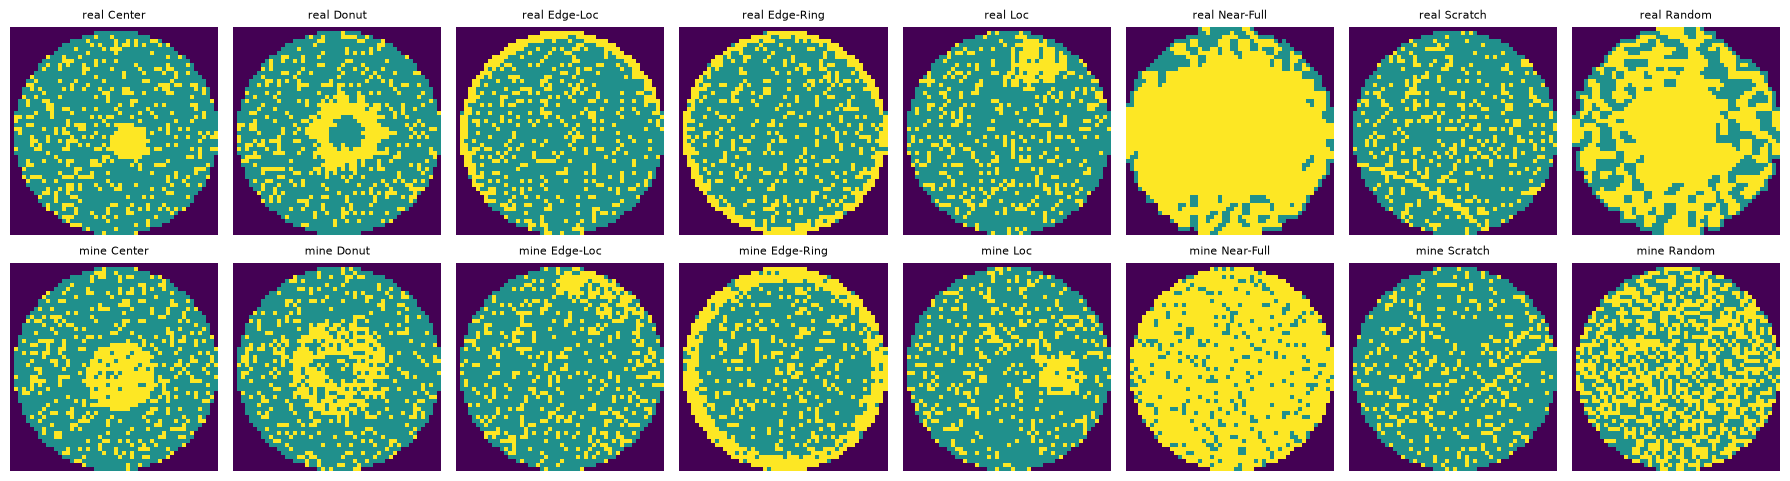

In [5]:
plt.figure(figsize=(18, 5))
for i in range(8):
    only_this = np.zeros(8, dtype=int)
    only_this[i] = 1
    # first real and first generated wafer with only this defect. [0][0] = positions out of the tuple, then the first one
    real = np.where((y_train == only_this).all(axis=1))[0][0]
    mine = np.where((gen_labels == only_this).all(axis=1))[0][0]

    plt.subplot(2, 8, i + 1) # top row real
    plt.imshow(maps_train[real])
    plt.title(f"real {wafer.DEFECTS[i]}", fontsize=8)
    plt.axis("off")
    plt.subplot(2, 8, i + 9) # bottom row mine
    plt.imshow(gen_maps[mine])
    plt.title(f"mine {wafer.DEFECTS[i]}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

**What to look for:** do mine look like the real ones? If one doesn't, change its rule in step 2.

## 5. Test the model on my wafers

In [6]:
gen_pred = forest.predict([wafer.features(m) for m in gen_maps])

recall_real = recall_score(p["y_test"], p["y_pred"], average=None)
recall_mine = recall_score(gen_labels, gen_pred, average=None)

for i in range(8):
    gap = (recall_real[i] - recall_mine[i]) * 100
    print(f"{wafer.DEFECTS[i]}: real test {recall_real[i] * 100:.1f}%, mine {recall_mine[i] * 100:.1f}%, gap {gap:.1f}")
print(f"All 8 right on mine: {accuracy_score(gen_labels, gen_pred) * 100:.1f}%")

Center: real test 93.3%, mine 71.8%, gap 21.5
Donut: real test 92.3%, mine 90.3%, gap 2.0
Edge-Loc: real test 84.2%, mine 86.3%, gap -2.1
Edge-Ring: real test 94.9%, mine 95.7%, gap -0.8
Loc: real test 87.7%, mine 45.9%, gap 41.8
Near-Full: real test 85.0%, mine 100.0%, gap -15.0
Scratch: real test 85.7%, mine 37.6%, gap 48.2
Random: real test 72.8%, mine 100.0%, gap -27.2
All 8 right on mine: 31.3%


**What to look for:** the biggest gap, next to the 15 points allowed.

## 6. Save

In [7]:
np.savez_compressed("output/generated.npz", maps=gen_maps, labels=gen_labels, predicted=gen_pred)
print("Saved output/generated.npz")

Saved output/generated.npz
